<a href="https://colab.research.google.com/github/cristobalcresposandoval-lang/CSN/blob/main/core_proyecto_1_parte_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

El archivo 'ventas.csv' no se encontró en el entorno. Generando un dataset sintético equivalente para demostración...
Dataset cargado correctamente
Cantidad de registros cargados: 200

ESTADISTICAS DESCRIPTIVAS BASICAS
         Cantidad  Precio_Unitario  Ingreso_Total
count  200.000000       200.000000     200.000000
mean     4.725000        84.640000     399.375000
std      2.606404       182.429804    1041.237891
min      1.000000        15.000000      15.000000
25%      2.000000        15.000000      75.000000
50%      5.000000        25.000000     135.000000
75%      7.000000       150.000000     247.500000
max      9.000000       999.000000    8991.000000

INFORMACION DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Fecha            200 non-null    datetime64[ns]
 1   Producto         200 non-null    objec

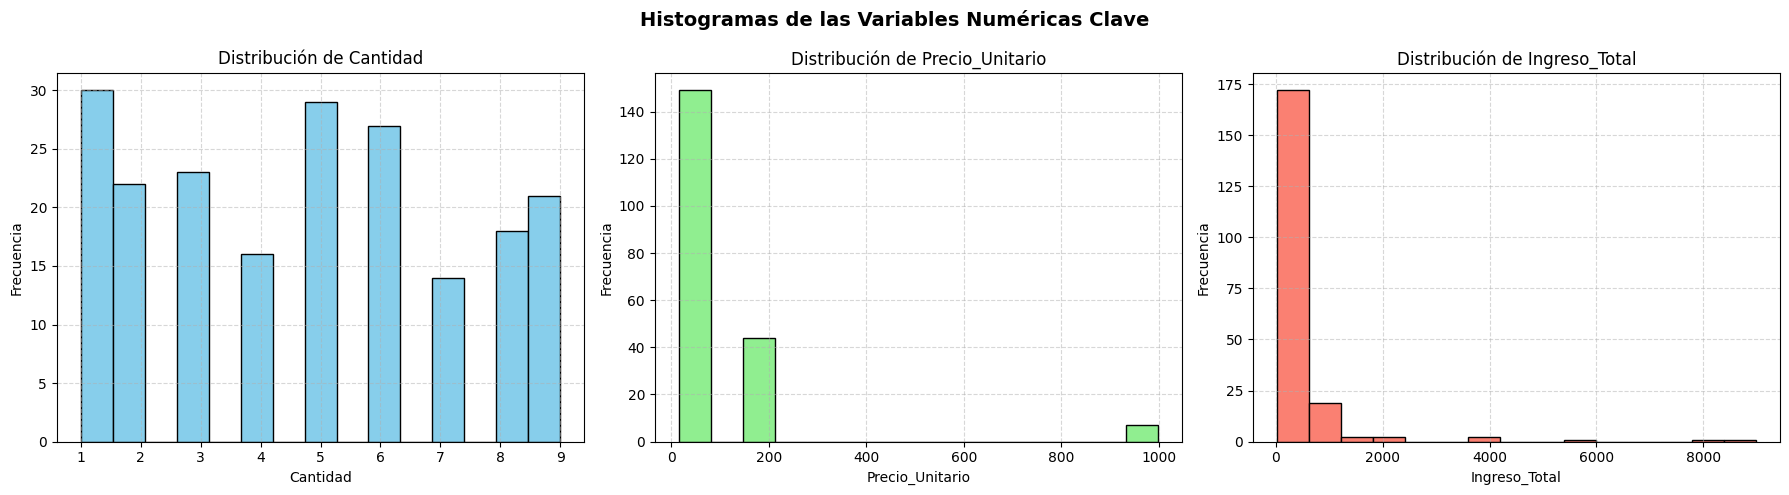

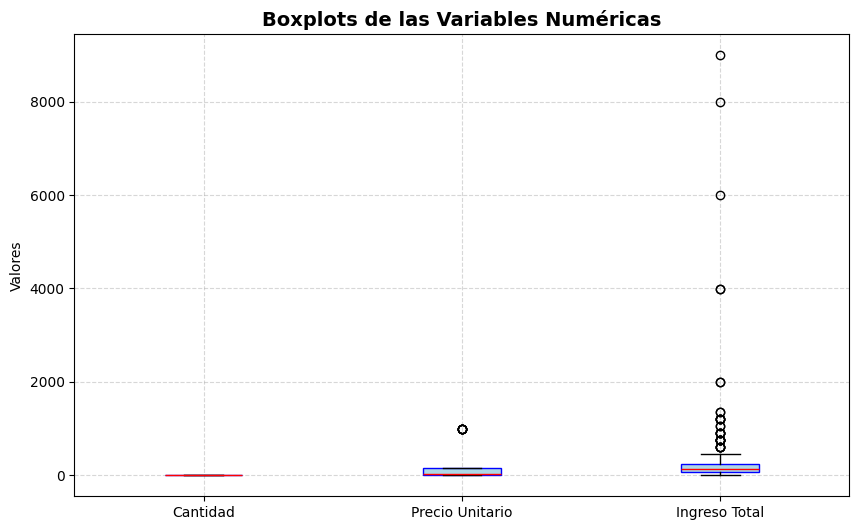

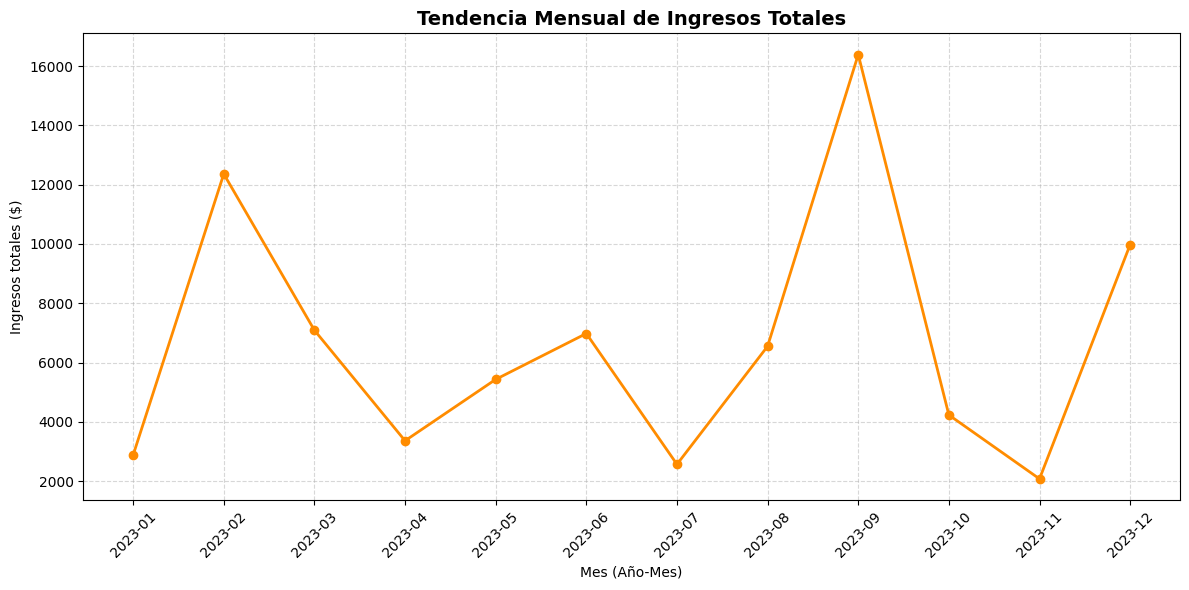

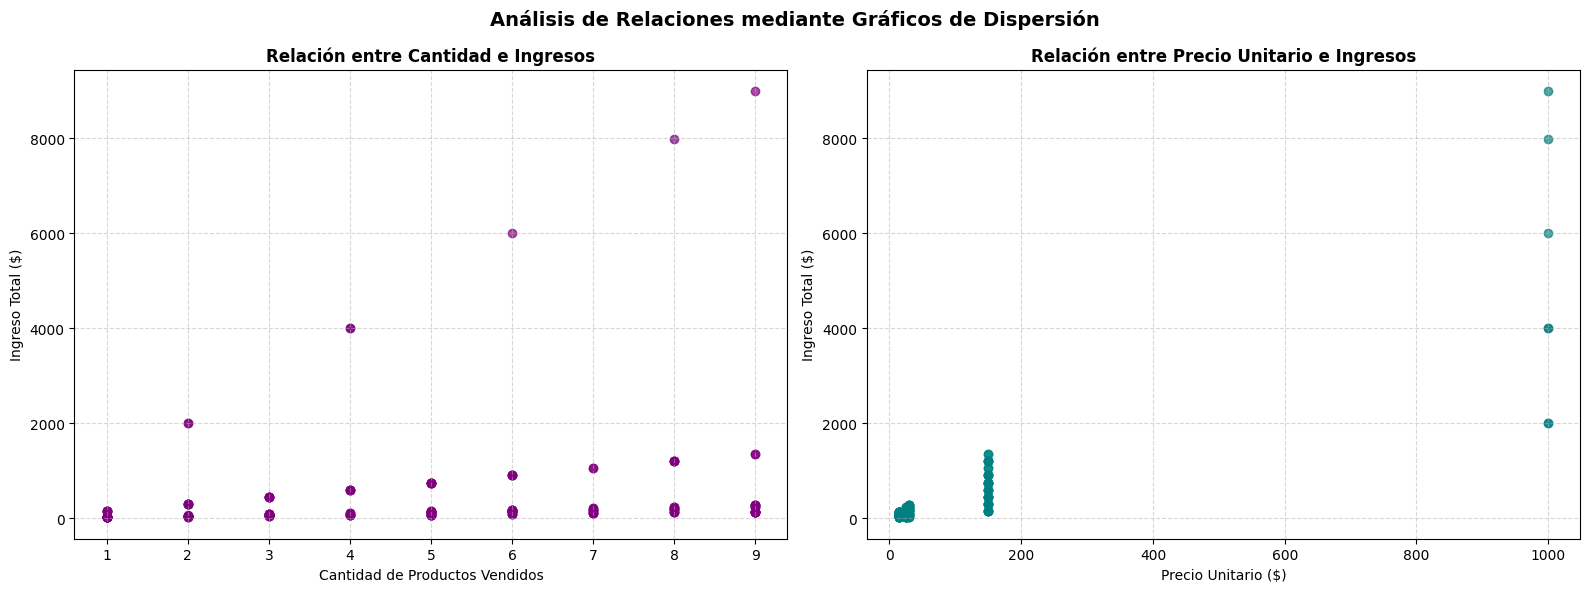

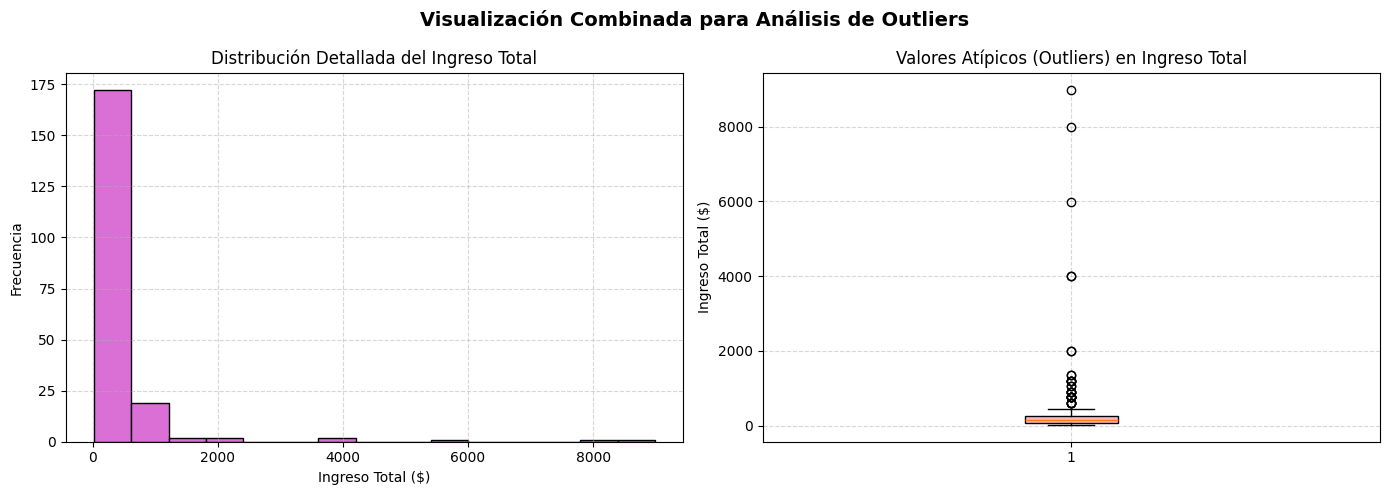


ANALISIS FORMAL DE VALORES ATIPICOS (IQR)
Primer cuartil (Q1): 75.0
Tercer cuartil (Q3): 247.5
Rango intercuartil (IQR): 172.5
Límite inferior para outliers: -183.75
Límite superior para outliers: 506.25
Cantidad de valores atípicos detectados: 33

Muestra de valores atípicos detectados:


,Fecha,Producto,Tienda,Ingreso_Total
2,2023-09-28,Laptop,Tienda Sur,7992.0
8,2023-05-02,Teclado,Tienda Sur,1350.0
14,2023-06-01,Mouse,Tienda Sur,1050.0
20,2023-10-21,Mouse,Tienda Sur,1200.0
30,2023-02-28,Mouse,Tienda Norte,900.0
33,2023-09-28,Monitor,Tienda Sur,750.0
40,2023-11-16,Mouse,Tienda Norte,600.0
56,2023-04-02,Laptop,Tienda Sur,1200.0
57,2023-09-21,Monitor,Tienda Sur,3996.0
62,2023-12-26,Monitor,Tienda Sur,3996.0



RESUMEN FINAL DE LA PARTE IV
Total de transacciones analizadas: 200
Ingresos acumulados totales: $79,875.00
Ingreso promedio por transacción: $399.38
Producto líder en generación de ingresos: Monitor
Tienda con mayor rendimiento comercial: Tienda Sur
Porcentaje de registros atípicos: 16.50%

PARTE IV COMPLETADA Y LISTA PARA REVISION


In [3]:
# =====================================================
# PARTE IV: ANALISIS EXPLORATORIO DE DATOS (EDA)
# Y VISUALIZACION
# =====================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. VERIFICAR O CREAR EL DATASET DE LA PARTE III
# =====================================================

# Si el archivo no está en el directorio raíz, buscamos recursivamente por si está dentro de la carpeta clonada de GitHub
file_name = "ventas.csv"
if not os.path.exists(file_name):
    encontrado = False
    for root, dirs, files in os.walk("."):
        if file_name in files:
            file_name = os.path.join(root, file_name)
            encontrado = True
            break
    if not encontrado:
        print(f"El archivo '{file_name}' no se encontró en el entorno. Generando un dataset sintético equivalente para demostración...")
        np.random.seed(42)
        fechas = pd.date_range(start="2023-01-01", end="2023-12-31", freq="D")
        productos = ["Laptop", "Teclado", "Mouse", "Monitor", "Auriculares"]
        tiendas = ["Tienda Norte", "Tienda Sur", "Tienda Centro"]

        data_demo = {
            "Fecha": np.random.choice(fechas, size=200),
            "Producto": np.random.choice(productos, size=200),
            "Tienda": np.random.choice(tiendas, size=200),
            "Cantidad": np.random.randint(1, 10, size=200),
            "Precio_Unitario": np.random.choice([15.0, 25.0, 150.0, 30.0, 999.0], size=200, p=[0.3, 0.3, 0.2, 0.15, 0.05])
        }
        df_demo = pd.DataFrame(data_demo)
        df_demo.to_csv("ventas.csv", index=False)
        file_name = "ventas.csv"

# Cargar dataset
df = pd.read_csv(file_name)

# Limpiar y preparar los datos
df = df.drop_duplicates()

df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
df["Cantidad"] = pd.to_numeric(df["Cantidad"], errors="coerce")
df["Precio_Unitario"] = pd.to_numeric(df["Precio_Unitario"], errors="coerce")

df = df.dropna(subset=["Fecha", "Cantidad", "Precio_Unitario", "Producto", "Tienda"])

# Calcular ingresos totales
df["Ingreso_Total"] = df["Cantidad"] * df["Precio_Unitario"]

print("Dataset cargado correctamente")
print("Cantidad de registros cargados:", len(df))

# =====================================================
# 2. ANALISIS DESCRIPTIVO
# =====================================================

print("\n" + "="*40)
print("ESTADISTICAS DESCRIPTIVAS BASICAS")
print("="*40)
print(df[["Cantidad", "Precio_Unitario", "Ingreso_Total"]].describe())

print("\n" + "="*40)
print("INFORMACION DEL DATASET")
print("="*40)
df.info()

print("\n" + "="*40)
print("VENTAS POR PRODUCTO")
print("="*40)
print(df.groupby("Producto")["Ingreso_Total"].sum().sort_values(ascending=False))

print("\n" + "="*40)
print("VENTAS POR TIENDA")
print("="*40)
print(df.groupby("Tienda")["Ingreso_Total"].sum().sort_values(ascending=False))

# =====================================================
# 3. HISTOGRAMAS DE VARIABLES NUMERICAS
# =====================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
columnas = ["Cantidad", "Precio_Unitario", "Ingreso_Total"]
colores = ["skyblue", "lightgreen", "salmon"]

for i, columna in enumerate(columnas):
    axes[i].hist(df[columna], bins=15, edgecolor="black", color=colores[i])
    axes[i].set_title(f"Distribución de {columna}", fontsize=12)
    axes[i].set_xlabel(columna)
    axes[i].set_ylabel("Frecuencia")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Histogramas de las Variables Numéricas Clave", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# =====================================================
# 4. BOXPLOTS DE VARIABLES NUMERICAS
# =====================================================

plt.figure(figsize=(10, 6))
plt.boxplot(
    [df["Cantidad"], df["Precio_Unitario"], df["Ingreso_Total"]],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", color="blue"),
    medianprops=dict(color="red"),
    tick_labels=["Cantidad", "Precio Unitario", "Ingreso Total"]
)
plt.title("Boxplots de las Variables Numéricas", fontsize=14, fontweight="bold")
plt.ylabel("Valores")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# =====================================================
# 5. GRAFICO DE LINEAS: TENDENCIA DE VENTAS
# =====================================================

ventas_mensuales = df.groupby(df["Fecha"].dt.to_period("M"))["Ingreso_Total"].sum()

plt.figure(figsize=(12, 6))
plt.plot(
    ventas_mensuales.index.astype(str),
    ventas_mensuales.values,
    marker="o",
    linestyle="-",
    color="darkorange",
    linewidth=2
)
plt.title("Tendencia Mensual de Ingresos Totales", fontsize=14, fontweight="bold")
plt.xlabel("Mes (Año-Mes)")
plt.ylabel("Ingresos totales ($)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# =====================================================
# 6. GRAFICO DE DISPERSION: VARIABLES VS INGRESOS
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Cantidad vs Ingreso_Total
axes[0].scatter(df["Cantidad"], df["Ingreso_Total"], alpha=0.7, color="purple")
axes[0].set_title("Relación entre Cantidad e Ingresos", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Cantidad de Productos Vendidos")
axes[0].set_ylabel("Ingreso Total ($)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Precio_Unitario vs Ingreso_Total
axes[1].scatter(df["Precio_Unitario"], df["Ingreso_Total"], alpha=0.7, color="teal")
axes[1].set_title("Relación entre Precio Unitario e Ingresos", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Precio Unitario ($)")
axes[1].set_ylabel("Ingreso Total ($)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Análisis de Relaciones mediante Gráficos de Dispersión", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# =====================================================
# 7. COMBINAR HISTOGRAMA Y BOXPLOT DE VENTAS
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
axes[0].hist(df["Ingreso_Total"], bins=15, edgecolor="black", color="orchid")
axes[0].set_title("Distribución Detallada del Ingreso Total", fontsize=12)
axes[0].set_xlabel("Ingreso Total ($)")
axes[0].set_ylabel("Frecuencia")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Boxplot
axes[1].boxplot(df["Ingreso_Total"], patch_artist=True, boxprops=dict(facecolor="lightpink"))
axes[1].set_title("Valores Atípicos (Outliers) en Ingreso Total", fontsize=12)
axes[1].set_ylabel("Ingreso Total ($)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Visualización Combinada para Análisis de Outliers", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# =====================================================
# 8. DETECCION DE VALORES ATIPICOS CON METODO IQR
# =====================================================

Q1 = df["Ingreso_Total"].quantile(0.25)
Q3 = df["Ingreso_Total"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

valores_atipicos = df[
    (df["Ingreso_Total"] < limite_inferior) |
    (df["Ingreso_Total"] > limite_superior)
]

print("\n" + "="*40)
print("ANALISIS FORMAL DE VALORES ATIPICOS (IQR)")
print("="*40)
print("Primer cuartil (Q1):", Q1)
print("Tercer cuartil (Q3):", Q3)
print("Rango intercuartil (IQR):", IQR)
print("Límite inferior para outliers:", limite_inferior)
print("Límite superior para outliers:", limite_superior)
print("Cantidad de valores atípicos detectados:", len(valores_atipicos))

if len(valores_atipicos) > 0:
    print("\nMuestra de valores atípicos detectados:")
    display(valores_atipicos[["Fecha", "Producto", "Tienda", "Ingreso_Total"]].head(10))

# =====================================================
# 9. RESUMEN FINAL DEL ANALISIS
# =====================================================

print("\n" + "="*40)
print("RESUMEN FINAL DE LA PARTE IV")
print("="*40)
print("Total de transacciones analizadas:", len(df))
print(f"Ingresos acumulados totales: ${df['Ingreso_Total'].sum():,.2f}")
print(f"Ingreso promedio por transacción: ${df['Ingreso_Total'].mean():,.2f}")
print("Producto líder en generación de ingresos:", df.groupby("Producto")["Ingreso_Total"].sum().idxmax())
print("Tienda con mayor rendimiento comercial:", df.groupby("Tienda")["Ingreso_Total"].sum().idxmax())
print("Porcentaje de registros atípicos:", f"{(len(valores_atipicos) / len(df)) * 100:.2f}%")

print("\nPARTE IV COMPLETADA Y LISTA PARA REVISION")